In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from textwrap import wrap
import concurrent
import multiprocessing
from scipy import stats
### Note: Adjust max_concurrent_processes based on your system capabilities
MAX_CONCURRENT_PROCESSES = multiprocessing.cpu_count()

# Read Required files

In [3]:
vm = pd.read_csv("data/vm.csv")
vmType = pd.read_csv("data/vmType.csv")

In [49]:
def calculate_active_time(data):
    duplicate = data['timeStamp'] 
    duplicate = pd.concat([duplicate[1:], pd.Series([14])]).reset_index(drop = True)
    data['afterTime'] = duplicate
    data['activeTime'] = (data['afterTime'] - data['timeStamp']) * data['nBin']
    total = data['activeTime'].sum()
    return total

In [50]:
mapping = {}
for index, df in vmType.groupby('machineId'):
    if index == 17: # empty requests
        continue
    if index == 20: # empty requests
        continue
    if index == 33: # crash 
        continue
    
    df_list = df.vmTypeId.to_list()
    yes = True
    
    for k,v in mapping.items():
        if(index == 30):
            break
        if(set(v) == set(df_list)):
            print(index, k)
            yes = False
            break
        
    if yes:
        mapping[index] = df_list
validIds = list(mapping.keys())
print(validIds)

print(len(validIds))

13 3
21 12
29 26
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 18, 19, 22, 23, 24, 25, 26, 27, 28, 30, 31, 32, 34]
29


In [51]:
def valid(data):
    # if data[(data.timeStamp < 0) | (data.timeStamp > 14)].shape[0] != 0:
    #     return False
    if data['nBin'][0] != 1 or data['nBin'][data.shape[0] - 1] != 0:
        return False
    return True

In [52]:
nclairalgo = ["FirstFit", "BestFit", "NextFit", "RRNextFit", "MRU"]
bestfit = ["BestFit_L1", "BestFit_L2", "BestFit_Linf"]
LA = ["LA_binary", "LA_logsecond"]
HA = ["HA", "Reduced_HA", "HA_DirectSum","Reduced_HA_DirectSum"]
RCP =["RCP", "RCP_NOLARGE", "PPE", "PPE_NOLARGE"]
NRT = ["NRT", "PrioritizedNRT"]
clairalgo = ["Classifybydeparture", "Classifybyduration","Reduced_HA", "LA", "Greedy", "PrioritizedNRT"]
learningalgo = ["RCP", "LA",  "Greedy", "PrioritizedNRT"]
lower = ["lowerbound"]
CBDU = ["Classifybyduration_p_" + str(p) for p in [1.25, 1.5, 2, 3, 4, 5, 8]]
CBDE = ["Classifybydeparture_p_" + str(p) for p in [0.0625, 0.125, 0.25, 0.5, 1, 2, 4, 8]]

In [ ]:
## Read CBD two.

activeTimeCB = {}
need = []
for algo in CBDE + CBDU:
    if activeTimeCB.get(algo) != None:
        continue
    
    activeTimeCB[algo] = [i for i in validIds]
    need.append(algo)

def analyse(algo, machineId, idx):
    try:
        data = pd.read_csv("generated/Results/" + algo + "_pId_" + str(machineId) + "_nbin.csv")
        lower = pd.read_csv("generated/Results/lowerbound_pId_" + str(machineId) + "_nbin.csv")
        data['timeStamp'] = lower['timeStamp']
           
        if not valid(data):
            print(machineId, algo, "Validate Failed")
            return
    except:
        print(machineId, algo, "Got Problem")
        return 
    # print(algo)
    activeTimeCB[algo][idx] = calculate_active_time(data)
    del data

idx = 0
futures = []
with concurrent.futures.ThreadPoolExecutor(max_workers=MAX_CONCURRENT_PROCESSES) as executor:
    for machineId in validIds:
        for algo in need:
            futures.append(executor.submit(analyse(algo, machineId, idx)))        
        idx += 1
    for future in concurrent.futures.as_completed(futures):
    # You can handle the result or exceptions here if needed
        future.result()

In [ ]:
## Read No Error

algorun = bestfit + ["FirstFit", "NextFit", "RRNextFit", "MRU"]
algorun += LA + HA + RCP + NRT + ["Classifybydeparture", "Classifybyduration", "Greedy"] + lower
activeTimenormal = {}

for algo in algorun:
    activeTimenormal[algo] = [0 for i in validIds]


def read_input(algo, idx, machineId):
    try:
        data = pd.read_csv("generated/Results/" + algo + "_pId_" + str(machineId) + "_nbin.csv")   
        lower = pd.read_csv("generated/Results/lowerbound_pId_" + str(machineId) + "_nbin.csv")
        data['timeStamp'] = lower['timeStamp']
        
        if not valid(data):
            print(machineId, algo, "Validate Failed")
            return
    except Exception as exp:
        print(machineId, algo, "Got Problem", exp)
        return
    activeTimenormal[algo][idx] = calculate_active_time(data)
    del data
    
with concurrent.futures.ThreadPoolExecutor(max_workers=MAX_CONCURRENT_PROCESSES) as executor:
    idx = 0
    futures = []
    for machineId in validIds:
        futures += [executor.submit(read_input, algo, idx, machineId) for algo in algorun] 
        idx += 1
    for future in concurrent.futures.as_completed(futures):
        # You can handle the result or exceptions here if needed
        future.result()


In [37]:
error_log = [0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 7.5, 10, 12.5, 15]

In [ ]:
## Log Normal error 
algorun_error = ["LA_binary", "LA_logsecond", 'Classifybydeparture', 'Classifybyduration', 'Reduced_HA', 'PrioritizedNRT',  'Greedy', 'RCP', 'RCP_NOLARGE', 'PPE', 'PPE_NOLARGE']

activeTimeerror = {}
for e in error_log:
    activeTimeerror[e] = {}
    for algo in algorun_error:
        activeTimeerror[e][algo] = [0 for i in validIds]


def read_input(e, algo, idx, machineId):
    try:
        data = pd.read_csv("generated/Results_e_log" + str(e) + "/" + algo + "_pId_" + str(machineId) + "_nbin.csv")   
        lower = pd.read_csv("generated/Results/lowerbound_pId_" + str(machineId) + "_nbin.csv")
        data['timeStamp'] = lower['timeStamp']

        if not valid(data):
            print(machineId, algo, e, "Validate Failed")
            return
    except Exception as exp:
        print(machineId, algo, e, "Got Problem", exp)
        return
    activeTimeerror[e][algo][idx] = calculate_active_time(data)
    del data

with concurrent.futures.ThreadPoolExecutor(max_workers=MAX_CONCURRENT_PROCESSES) as executor:
    idx = 0
    futures = []
    for machineId in validIds:
        futures += [executor.submit(read_input, e, algo, idx, machineId) for e in error_log for algo in algorun_error] 
        idx += 1
    for future in concurrent.futures.as_completed(futures):
        # You can handle the result or exceptions here if needed
        future.result()

## Compile all result to a single csv

In [ ]:
activeTime = pd.DataFrame(activeTimenormal)
activeTime['error'] = [0 for i in validIds]
activeTime['pId'] = validIds 

In [ ]:
for e in error_log:
    temp = pd.DataFrame(activeTimeerror[e])
    temp['error'] = [e for i in validIds]
    temp['pId'] = validIds 
    activeTime = pd.concat([activeTime, temp]).reset_index(drop = True)
activeTime

In [ ]:
activeTimetemp = activeTime.copy()
activeTimetemp['pId'] = 1
for column in activeTimetemp.columns:
    if column == 'pId':
        continue
    if column == 'error':
        continue
    activeTimetemp[column] = activeTimetemp[column] - [1,1]
activeTime = pd.concat([activeTime, activeTimetemp]).reset_index(drop = True)

In [ ]:
activeTimeCB_df = pd.DataFrame(activeTimeCB)
activeTimeCB_df['error'] = [0 for i in validIds]
activeTimeCB_df['pId'] = validIds 

# Generate Figures

In [12]:
plt.rcParams.update({
    'font.size': 12, 
    "text.usetex": False, 
    "font.family": "serif",}
)
plt.rc('text.latex', preamble=r'\usepackage{amsmath} \usepackage{amssymb}')
meanprops = {
    "marker": "s",       # Shape of the mean marker
    "markerfacecolor": "red",  # Color of the mean marker
    "markeredgecolor": "black",
    "markersize": 10      # Size of the mean marker
}
## Best put 17

# Analyse Duration information

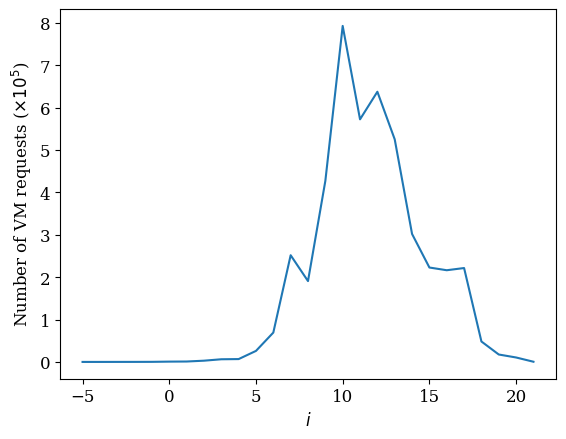

In [13]:
temp = vm[(vm.starttime >= 0) & (vm.endtime <= 14)]
dur = temp['endtime'] - temp['starttime']
dist = (np.floor(np.log2(dur * 24 * 3600)) + 1).value_counts().sort_index()

x = dist.index
y = dist.values / 10 ** 5

plt.plot(x,y)
plt.ylabel("Number of VM requests ($\\times 10^5$)")
plt.xlabel("$i$")
plt.savefig("analyzer/figure1a.png", bbox_inches='tight')
plt.show()

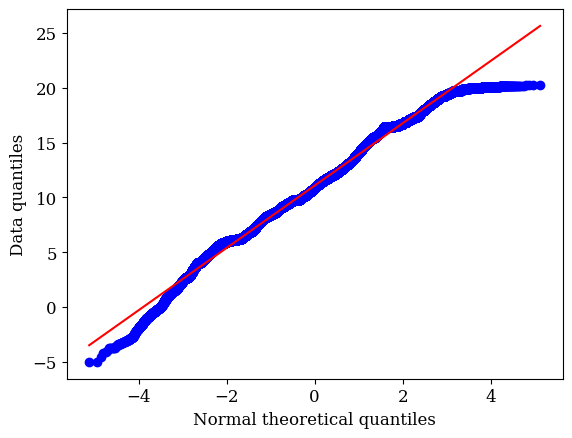

In [14]:
temp = vm[(vm.starttime >= 0) & (vm.endtime <= 14)]
dur = temp['endtime'] - temp['starttime']
dist = (np.log2(dur * 24 * 3600))
stats.probplot(dist, dist='norm', plot=plt)
plt.title("")
plt.ylabel("Data quantiles")
plt.xlabel("Normal theoretical quantiles")
plt.savefig("analyzer/figure1b.png", bbox_inches='tight')
plt.show()

# Analyse Performance Ratio (Box Plot)

In [ ]:
lower_base = activeTime[(activeTime.error == 0) & (activeTime.pId != 18)].lowerbound

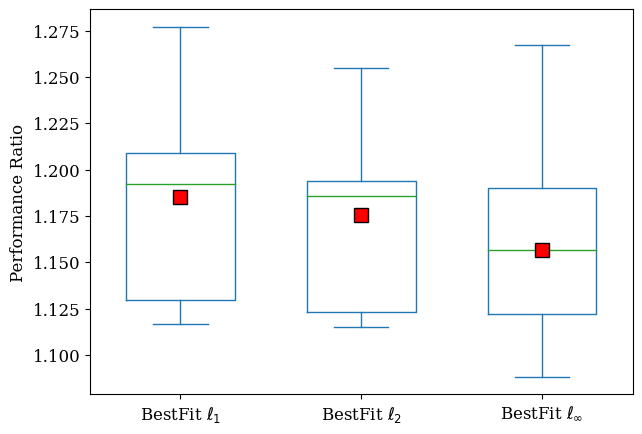

<Figure size 640x480 with 0 Axes>

In [23]:
plot_df = activeTime[(activeTime.error == 0) & (activeTime.pId != 18)][bestfit]
plot_df = plot_df.divide(lower_base, axis = 0)

plot_df.plot(kind='box',figsize = (7, 5), widths = 0.6, showmeans = True, meanprops = meanprops)

labels = [r"BestFit $\ell_1$", r"BestFit $\ell_2$", r"BestFit $\ell_\infty$"]

plt.ylabel("Performance Ratio")
plt.xticks([i for i in range(1, 1 + len(labels))],labels)
plt.plot([], [], 's', linewidth=1, markerfacecolor='red', markeredgecolor = 'black', label='mean')
plt.plot([], [], '-', linewidth=1, color='green', label='median')
plt.savefig("analyzer/figure2.png", bbox_inches='tight')
plt.show()
plt.clf()

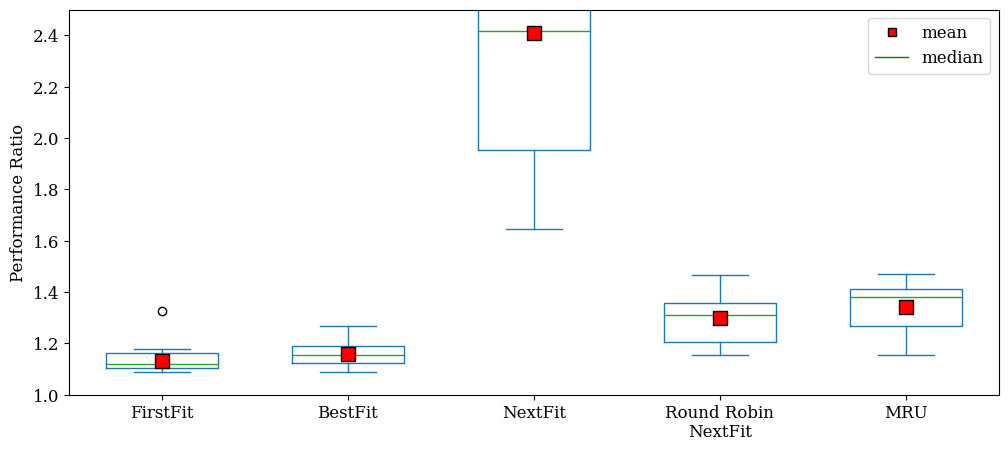

<Figure size 640x480 with 0 Axes>

In [25]:
activeTime["BestFit"] = activeTime["BestFit_Linf"]
nclair = activeTime[(activeTime.error == 0) & (activeTime.pId != 18)][nclairalgo]
nclair = nclair.divide(lower_base, axis = 0)
nclair = nclair.rename(columns={"RRNextFit": "Round Robin NextFit"})

nclair.plot(kind='box',figsize = (12, 5), widths = 0.6, showmeans = True, meanprops=meanprops)
labels = nclair.columns

labels = ['\n'.join(wrap(l, 12)) for l in labels]

plt.ylabel("Performance Ratio")
plt.xticks([i for i in range(1, 1 + len(labels))],labels)
plt.ylim(bottom = 1, top = 2.5)
plt.plot([], [], 's', linewidth=1, markerfacecolor='red', markeredgecolor = 'black', label='mean')
plt.plot([], [], '-', linewidth=1, color='green', label='median')
plt.legend()
plt.savefig("analyzer/figure3.png", bbox_inches='tight')

plt.show()
plt.clf()

['0.0625', '0.125', '0.25', '0.5', '1', '2', '4', '8']


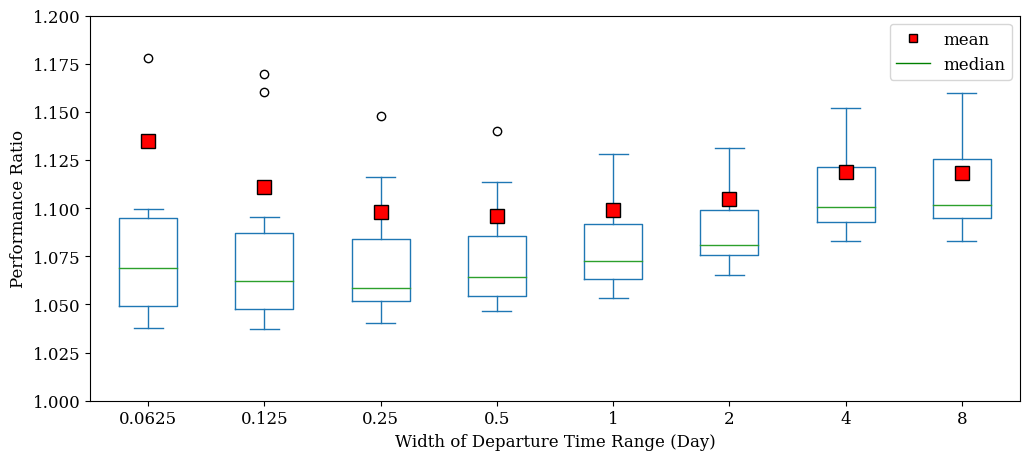

<Figure size 640x480 with 0 Axes>

In [26]:
depart = activeTimeCB_df[(activeTimeCB_df.error == 0) & (activeTimeCB_df.pId != 18)][CBDE]

depart = depart.divide(lower_base, axis = 0)
depart.plot(kind='box',figsize = (12, 5), showmeans=True, meanprops=meanprops)
labels = [name.split("_")[-1] for name in CBDE]
labels = ['\n'.join(wrap(l, 12)) for l in labels]
print(labels)
plt.plot([], [], 's', linewidth=1, markerfacecolor='red', markeredgecolor = 'black', label='mean')
plt.plot([], [], '-', linewidth=1, color='green', label='median')
plt.legend()
plt.xlabel("Width of Departure Time Range (Day)") 
plt.ylabel("Performance Ratio")
plt.xticks([i for i in range(1, 1 + len(labels))],labels)
plt.ylim((1,1.2))
plt.savefig("analyzer/figure4.png", bbox_inches='tight')
plt.show()
plt.clf()


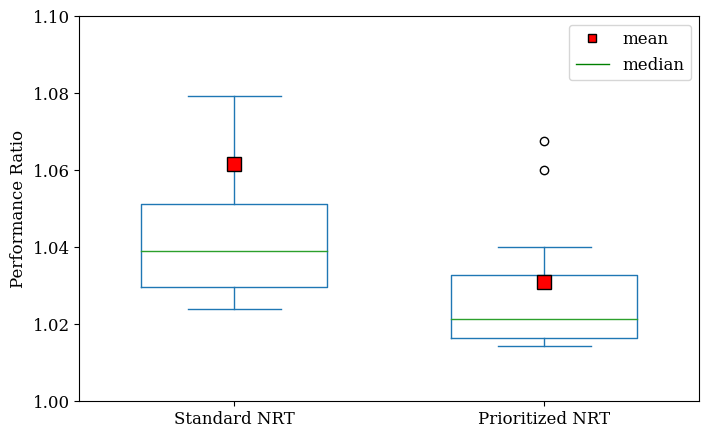

<Figure size 640x480 with 0 Axes>

In [29]:
clair = activeTime[(activeTime.error == 0) & (activeTime.pId != 18)][NRT]
clair = clair.divide(lower_base, axis = 0)
clair.rename(columns={
    "NRT" : "Standard NRT",
    "PrioritizedNRT" : "Prioritized NRT"
}, inplace = True)
clair.plot(kind='box',figsize = (8, 5), widths=0.6, showmeans=True, meanprops=meanprops)
labels = clair.columns
labels = ['\n'.join(wrap(l, 24)) for l in labels]

plt.ylabel("Performance Ratio")
plt.xticks([i for i in range(1, 1 + len(labels))],labels)
plt.ylim(bottom = 1, top = 1.1)
plt.plot([], [], 's', linewidth=1, markerfacecolor='red', markeredgecolor = 'black', label='mean')
plt.plot([], [], '-', linewidth=1, color='green', label='median')
plt.legend()
plt.savefig("analyzer/figure5.png", bbox_inches='tight')
plt.show()
plt.clf()

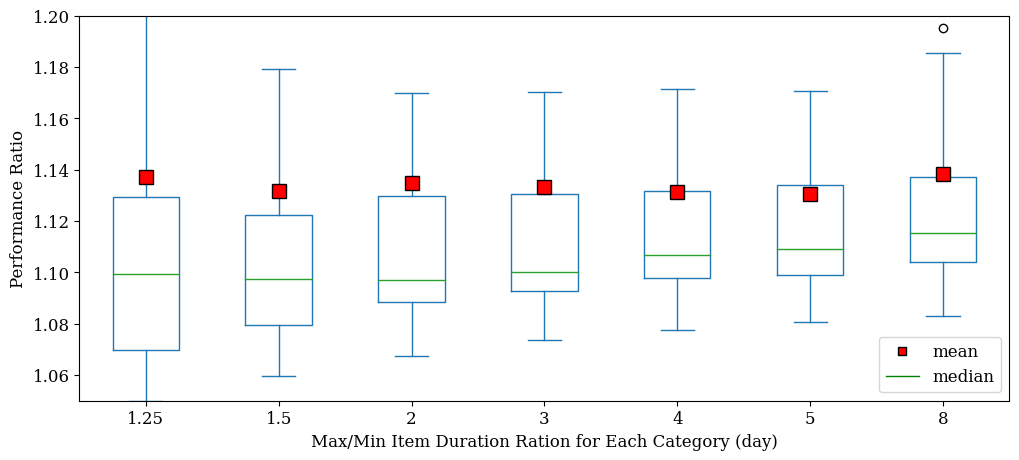

<Figure size 640x480 with 0 Axes>

In [30]:

duration = activeTimeCB_df[(activeTimeCB_df.error == 0) & (activeTimeCB_df.pId != 18)][CBDU]

duration = duration.divide(lower_base, axis = 0)
duration.plot(kind='box',figsize = (12, 5), showmeans=True, meanprops=meanprops)
labels = [name.split("_")[-1] for name in CBDU]
labels = ['\n'.join(wrap(l, 12)) for l in labels]
plt.xlabel("Max/Min Item Duration Ration for Each Category (day)") 
plt.ylabel("Performance Ratio")
plt.xticks([i for i in range(1, 1 + len(labels))],labels)
plt.plot([], [], 's', linewidth=1, markerfacecolor='red', markeredgecolor = 'black', label='mean')
plt.plot([], [], '-', linewidth=1, color='green', label='median')
plt.legend()
plt.ylim((1.05,1.2))
plt.savefig("analyzer/figure6.png", bbox_inches='tight')

plt.show()
plt.clf()



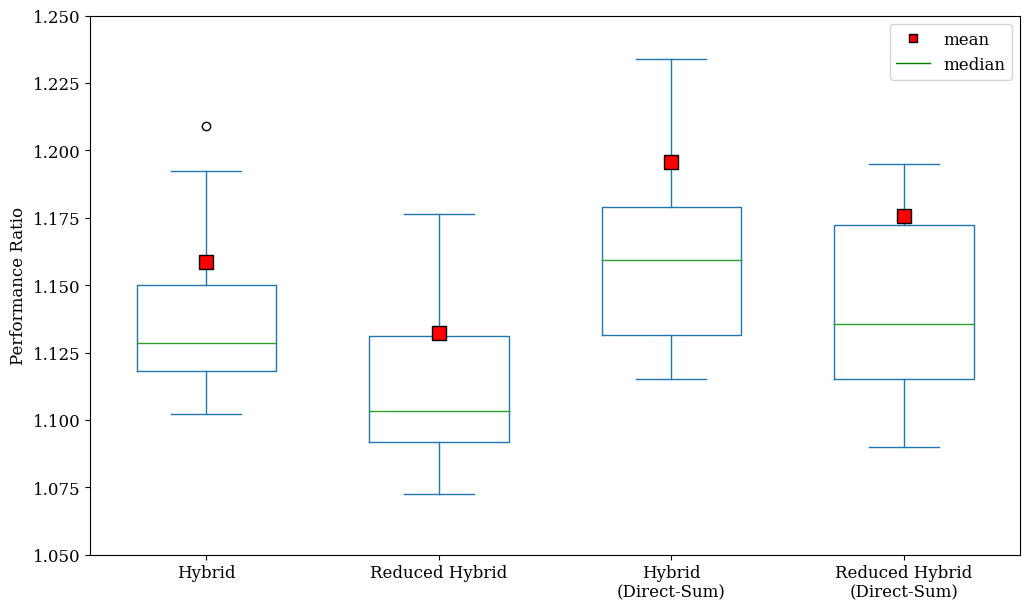

<Figure size 640x480 with 0 Axes>

In [31]:
clair = activeTime[(activeTime.error == 0) & (activeTime.pId != 18)][HA]

clair = clair.divide(lower_base, axis = 0)
clair.plot(kind='box',figsize = (12, 7), widths= 0.6,showmeans = True, meanprops=meanprops)
labels = ['Hybrid', 'Reduced Hybrid', 'Hybrid\n(Direct-Sum)', 'Reduced Hybrid\n(Direct-Sum)']

plt.ylabel("Performance Ratio")

plt.xticks([i for i in range(1, 1 + len(labels))],labels)
plt.ylim(bottom = 1.05, top = 1.25)
plt.plot([], [], 's', linewidth=1, markerfacecolor='red', markeredgecolor = 'black', label='mean')
plt.plot([], [], '-', linewidth=1, color='green', label='median')

plt.legend()
plt.savefig("analyzer/figure7.png", bbox_inches='tight')

plt.show()
plt.clf()


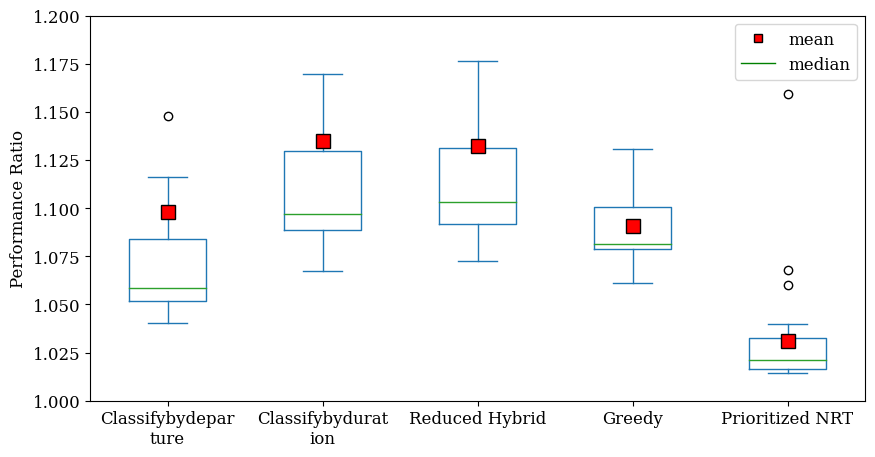

<Figure size 640x480 with 0 Axes>

In [34]:
clair = activeTime[(activeTime.pId != 18) & (activeTime.error == 0)][[
    'Classifybydeparture',
    'Classifybyduration',
    'Reduced_HA',
    'Greedy',
    'PrioritizedNRT']]


clair = clair.divide(lower_base, axis = 0)
clair = clair.rename( columns = {
    "PrioritizedNRT":"Prioritized NRT",
    "Reduced_HA":  "Reduced Hybrid"
})

clair.plot(kind='box',figsize = (10, 5), showmeans = True, meanprops=meanprops)
labels = clair.columns
labels = ['\n'.join(wrap(l, 15)) for l in labels]
plt.ylabel("Performance Ratio")
plt.xticks([i for i in range(1, 1 + len(labels))],labels)
plt.ylim(bottom = 1, top = 1.2)
plt.plot([], [], 's', linewidth=1, markerfacecolor='red', markeredgecolor = 'black', label='mean')
plt.plot([], [], '-', linewidth=1, color='green', label='median')
plt.legend()
plt.savefig("analyzer/figure8.png", bbox_inches='tight')
plt.show()
plt.clf()

## Learning Augmented Settings

In [35]:
algorithm_colors = {
    "First Fit": "black",
    "RCP": "blue",
    "RCP_NOLARGE": "dodgerblue",
    "PPE": "green",
    "PPE_NOLARGE": "darkolivegreen",
    "LA_binary": "gold",
    "LA_logsecond": "brown",
    "Classifybyduration": "red",
    "Classifybydeparture": "darkgreen",
    "Greedy": "purple",
    "BestCRT": "magenta",
    "Reduced_HA": "teal",
}

present_name = {
    "FirstFit": "FirstFit",
    "RCP": "RCP",
    "RCP_NOLARGE": "RCP Without Large Bin",
    "PPE": "PPE",
    "PPE_NOLARGE": "PPE Without Large Bin",
    "LA_binary": "LA (Binary Classification)",
    "LA_logsecond": "LA (Geometric Ranges)",
    "Classifybyduration": "Classify By Duration",
    "Classifybydeparture": "Classify By Departure Time",
    "Greedy": "Greedy",
    "PrioritizedNRT": "Prioritized NRT",
    "Reduced_HA": "Reduced Hybrid",
}

In [ ]:
imptalgo = ["Classifybyduration", "Classifybydeparture", "Greedy", "PrioritizedNRT", "Reduced_HA",
            "LA_binary", "LA_logsecond", "RCP", "RCP_NOLARGE", "PPE", "PPE_NOLARGE"]

mean_df = {}
for e in [0] + error_log:
    temp = activeTime[(activeTime.error == e) & (activeTime.pId != 18)][imptalgo].reset_index(drop = True)
    temp = temp.divide(lower_base, axis = 0)
    mean_df[e] = temp.mean()
mean_df = pd.DataFrame(mean_df).T.reset_index().rename(columns={'index':'error'})
firstfitmean = (activeTime[(activeTime.error == 0) & (activeTime.pId != 18)]['FirstFit'].reset_index(drop=True)/lower_base).mean()

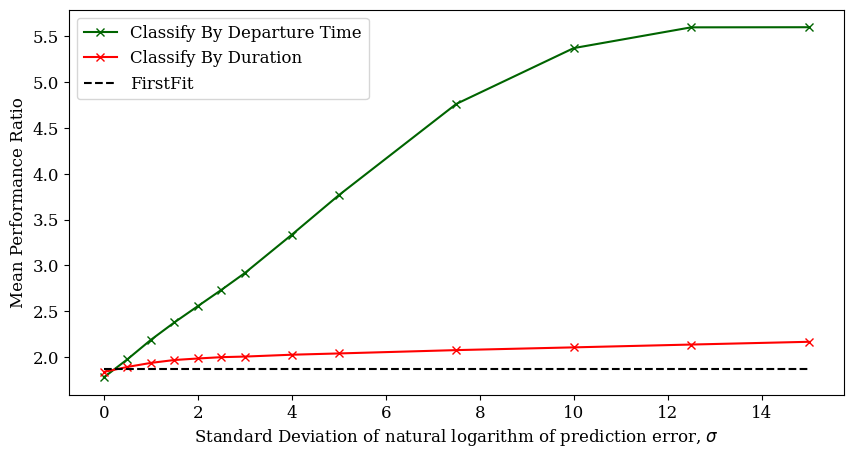

In [45]:
plt.figure(figsize=(10,5))

plot_df = mean_df[["error", "Classifybydeparture", "Classifybyduration"]]
for k in plot_df.columns:
    if k == 'error':
        continue
    plt.plot(plot_df['error'], plot_df[k], 'x-', label = present_name[k], color=algorithm_colors[k] )
plt.plot(plot_df['error'], [firstfitmean for _ in plot_df['error']], '--', label='FirstFit', color='black')
# plt.title("Results of Clairvoyant Algorithm across multiplicative error")
plt.legend()
plt.xlabel("Standard Deviation of natural logarithm of prediction error, $\sigma$")
plt.ylabel("Mean Performance Ratio")
plt.savefig("analyzer/figure9.png", bbox_inches='tight')

plt.show()


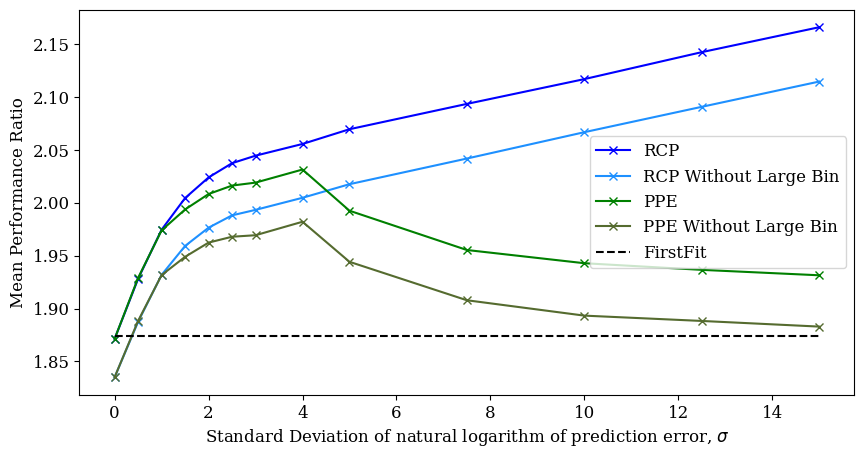

In [46]:
plt.figure(figsize=(10,5))
plot_df = mean_df[["error", "RCP", "RCP_NOLARGE", "PPE", "PPE_NOLARGE"]]
for k in plot_df.columns:
    if k == 'error':
        continue
    plt.plot(plot_df['error'], plot_df[k], 'x-', label = present_name[k], color = algorithm_colors[k])
plt.plot(plot_df['error'], [firstfitmean for _ in plot_df['error']], '--', label='FirstFit', color='black')
# plt.title("Results of Clairvoyant Algorithm across multiplicative error")
plt.legend()
plt.xlabel("Standard Deviation of natural logarithm of prediction error, $\sigma$")
plt.ylabel("Mean Performance Ratio")
plt.savefig("analyzer/figure10.png", bbox_inches='tight')

plt.show()


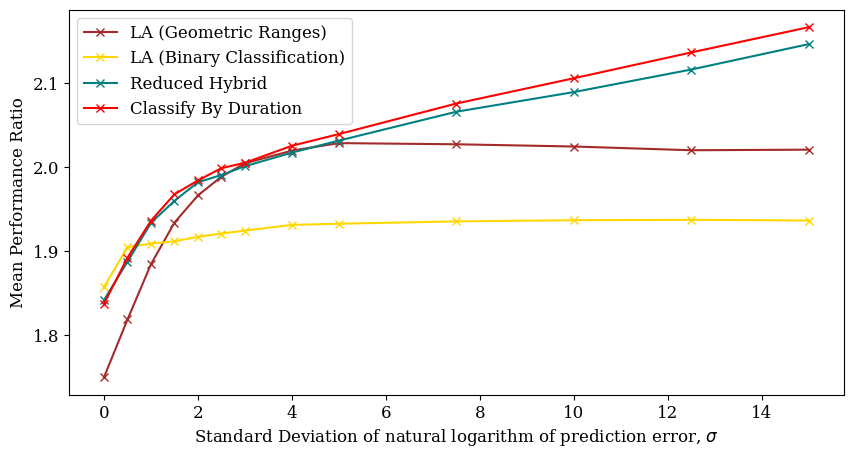

In [47]:
plt.figure(figsize=(10,5))
run_algo = ["LA_logsecond", "LA_binary", "Reduced_HA", "Classifybyduration"]
plot_df = mean_df

for algo in run_algo:
    plt.plot(plot_df['error'], mean_df[algo], 'x-', label = present_name[algo], color = algorithm_colors[algo])

plt.legend()
plt.xlabel("Standard Deviation of natural logarithm of prediction error, $\sigma$")
plt.ylabel("Mean Performance Ratio")
#plt.ylim(bottom = 1, top = 1.3)
#plt.xlim(left = 1, right = 100000)
plt.savefig("analyzer/figure11.png", bbox_inches='tight')

plt.show()


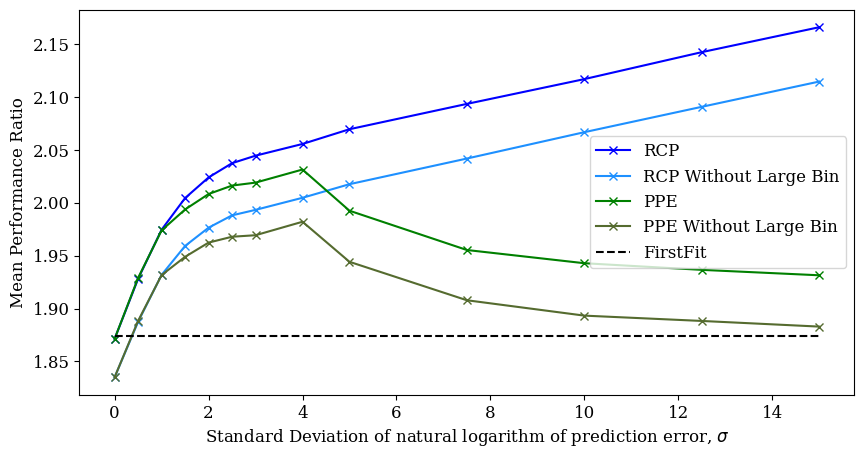

In [48]:
plt.figure(figsize=(10,5))
plot_df = mean_df[["error", "RCP", "RCP_NOLARGE", "PPE", "PPE_NOLARGE"]]
for k in plot_df.columns:
    if k == 'error':
        continue
    plt.plot(plot_df['error'], plot_df[k], 'x-', label = present_name[k], color = algorithm_colors[k])
plt.plot(plot_df['error'], [firstfitmean for _ in plot_df['error']], '--', label='FirstFit', color='black')
# plt.title("Results of Clairvoyant Algorithm across multiplicative error")
plt.legend()
plt.xlabel("Standard Deviation of natural logarithm of prediction error, $\sigma$")
plt.ylabel("Mean Performance Ratio")
plt.savefig("analyzer/figure12.png", bbox_inches='tight')

plt.show()
